# Simulations and Results

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/01-basics/03-simulations_and_results.ipynb)

All simulations of **udkm1Dsim** are initialized with a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>`, see the [structure example](#example_structure), and share the same conventions for their methods and results.
This example introduces these conventions for a short chain of a heat, phonon, and X-ray diffraction simulation of a SrRuO$_3$/SrTiO$_3$ superlattice on a SrTiO$_3$ substrate, whose optical superlattice phonon mode modulates the intensity of the superlattice Bragg peaks.

:::{note}
This example gives a general overview of how the simulations are used and how their results are handled.
It is not about the details of the simulations, which are explained in the following examples, e.g. of the [heat](#example_excitation_NTM), [phonons](#example_strain_pulses), and [X-ray diffraction](#example_dynamical_xray).
:::

<img src="./simulations_and_results.svg" alt="Flow of the simulations of this example and their results, which are passed on and cached in HDF5 files" class="align-center gallery_thumbnail" width="90%">

Every simulation is initialized with the structure.
Its `get_*()` methods return their results as {py:class}`Result <udkm1Dsim.simulations.result.Result>`, here named with the prefix `res_` to distinguish them from plain arrays, which are passed on to the following simulations and are cached as HDF5 files.

:::{versionchanged} 3.0.0
The `get_*()`, `homogeneous_*()`, and `inhomogeneous_*()` methods of the simulations return a {py:class}`Result <udkm1Dsim.simulations.result.Result>` instead of a plain array or a tuple of arrays, e.g. 

`temp_map, delta_temp_map = h.get_temp_map(delays, init_temp)`
becomes 

`res_temp = h.get_temp_map(delays, init_temp)` 

with `res_temp.temp_map` and `res_temp.delta_temp_map`.
The plain arrays are returned by the `calc_*()` methods, see below, and the results are cached as HDF5 files instead of `.npz` files.
:::

The methods of the simulations are named by what they return:

| method | returns | example |
|---|---|---|
| `get_*()` | {py:class}`Result <udkm1Dsim.simulations.result.Result>` with coordinates, units, and metadata, which is saved to and loaded from the cache | {py:meth}`get_temp_map <udkm1Dsim.simulations.heat.Heat.get_temp_map>` |
| `homogeneous_*()`, `inhomogeneous_*()` | {py:class}`Result <udkm1Dsim.simulations.result.Result>` of the scattering simulations for homogeneous sub-structures or for maps of every layer | {py:meth}`inhomogeneous_reflectivity <udkm1Dsim.simulations.scattering.dynamical.XrayDyn.inhomogeneous_reflectivity>` |
| `calc_*()` | plain numpy arrays of the actual calculation without cache, e.g. for fitting | {py:meth}`calc_temp_map <udkm1Dsim.simulations.heat.Heat.calc_temp_map>` |

The structures, layers, and atoms return plain values of the sample, either as properties without arguments, e.g. {py:attr}`layer_distances <udkm1Dsim.structures.structure.Structure.layer_distances>`, or by their `get_*()` methods with arguments, e.g. {py:meth}`get_layer_property_vector <udkm1Dsim.structures.structure.Structure.get_layer_property_vector>`.

## Setup

Do all necessary imports and settings.

In [1]:
import tempfile
from os import listdir, path

import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

A superlattice of 11 double layers (DL), each of 20 SrRuO$_3$ (SRO) and 38 SrTiO$_3$ (STO) unit cells, on a STO substrate, see the [structure example](#example_structure) for the details of the structure.
Only the SRO layers absorb the laser pulse, while the STO layers and the substrate are transparent.

In [2]:
O = ud.Atom("O")
Ti = ud.Atom("Ti")
Sr = ud.Atom("Sr")
Ru = ud.Atom("Ru")

# c-axis lattice constants of the three layers
c_STO_sub = 3.905 * u.angstrom
c_STO = 3.921 * u.angstrom
c_SRO = 3.94897 * u.angstrom

# SRO layer
SRO = ud.UnitCell(
    "SRO",
    "Strontium Ruthenate",
    lattice=ud.LatticeParameters(a_axis=c_STO_sub, b_axis=c_STO_sub, c_axis=c_SRO),
    thermal=ud.ThermalParameters(
        therm_cond=5.72 * u.W / (u.m * u.K),
        lin_therm_exp=1.03e-5,
        heat_capacity="455.2 + 0.112*T - 2.1935e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=6.312 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.44 + 1.32j)),
)
SRO.add_atom(O, 0)
SRO.add_atom(Sr, 0)
SRO.add_atom(O, 0.5)
SRO.add_atom(O, 0.5)
SRO.add_atom(Ru, 0.5)

# STO layer of the superlattice
STO = ud.UnitCell(
    "STO",
    "Strontium Titanate",
    lattice=ud.LatticeParameters(a_axis=c_STO_sub, b_axis=c_STO_sub, c_axis=c_STO),
    thermal=ud.ThermalParameters(
        therm_cond=12 * u.W / (u.m * u.K),
        lin_therm_exp=1e-5,
        heat_capacity="733.73 + 0.0248*T - 6.531e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=7.800 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.1 + 0j)),
)
STO.add_atom(O, 0)
STO.add_atom(Sr, 0)
STO.add_atom(O, 0.5)
STO.add_atom(O, 0.5)
STO.add_atom(Ti, 0.5)

# STO substrate
STO_sub = ud.UnitCell(
    "STOsub",
    "Strontium Titanate Substrate",
    lattice=ud.LatticeParameters(c_axis=c_STO_sub),  # a- and b-axis default to the c-axis
    thermal=ud.ThermalParameters(
        therm_cond=12 * u.W / (u.m * u.K),
        lin_therm_exp=1e-5,
        heat_capacity="733.73 + 0.0248*T - 6.531e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=7.800 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.1 + 0j)),
)
STO_sub.add_atom(O, 0)
STO_sub.add_atom(Sr, 0)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(Ti, 0.5)

DL = ud.Structure("DL: 20xSRO + 38xSTO")
DL.add_sub_structure(SRO, 20)  # add 20 unit cells of SRO
DL.add_sub_structure(STO, 38)  # add 38 unit cells of STO

S = ud.Structure("11xDL on STO")
S.add_sub_structure(DL, 11)  # add 11 double layers
S.add_sub_structure(STO_sub, 1000)  # add 1000 unit cells of dynamic STO
# add a static and semi-infinite STO substrate for the X-ray diffraction
S.add_substrate(STO_sub, 1000000)

## Heat

The second argument of every simulation is `force_recalc`.
For `force_recalc=False`, a result is loaded from the cache directory `cache_dir`, if it was calculated before with the same parameters, while `save_data=True` saves every calculated result there.
Here, the `cache_dir` is a temporary directory.

In [3]:
cache_dir = tempfile.mkdtemp()

h = ud.Heat(S, False)  # force_recalc=False loads cached results
h.cache_dir = cache_dir  # directory of the cached results
h.save_data = True  # save the calculated results to the cache_dir
h.disp_messages = True  # display messages of the calculation

h.excitation = {
    "fluence": [30] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0] * u.ps,
}
h.heat_diffusion = False  # no heat diffusion within the first picoseconds

delays = np.r_[-2:20:0.05] * u.ps

### Result

The {py:meth}`get_temp_map <udkm1Dsim.simulations.heat.Heat.get_temp_map>` method returns a {py:class}`Result <udkm1Dsim.simulations.result.Result>`, whose table lists its data and coordinates with their shapes, the names of their dimensions, and their units.

In [4]:
res_temp = h.get_temp_map(delays, 300 * u.K)
res_temp

Surface incidence fluence scaled by factor 1.0000 due to incidence angle theta=90.00 deg
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 18.4 % and transmission of 11.0 %.
Elapsed time for _temperature_after_delta_excitation_: 0.192195 s
Elapsed time for _temp_map_: 0.221942 s
_temp_map_ saved to file:
	 temp_map_bcb96d6a20d146e74f474ea6b8c12fff_04402a9633f6df253b536a5d3663120a.h5


name,alias,kind,shape,dims,unit
temp_map,,data,"(440, 1638)","delays, distances",K
delta_temp_map,,data,"(440, 1638)","delays, distances",K
init_temp,,data,"(1638, 1)","distances, subsystems",K
delays,,coord,"(440,)",delays,s
distances,,coord,"(1638,)",distances,m


The entries are accessed by their name as item or attribute and are plain numpy arrays in the given units.
The {py:meth}`quantity <udkm1Dsim.simulations.result.Result.quantity>` method returns an entry with its unit as pint quantity.

In [5]:
print(res_temp["temp_map"].shape)
print(res_temp.temp_map.shape)
print(res_temp.dims("temp_map"), res_temp.unit("temp_map"))
print(res_temp.quantity("distances").to("nm")[:3])

(440, 1638)
(440, 1638)
('delays', 'distances') K
[0.1974 0.5923 0.9872] nm


In contrast to the former tuples of arrays, a result cannot be unpacked, e.g. `temp_map, delta_temp_map = res_temp` raises a `TypeError`, since the order of its entries is not part of its meaning.
The data entries and the coordinates are held separately by {py:attr}`data <udkm1Dsim.simulations.result.Result.data>` and {py:attr}`coords <udkm1Dsim.simulations.result.Result.coords>` as dicts:

In [6]:
print(list(res_temp.data))
print(list(res_temp.coords))

['temp_map', 'delta_temp_map', 'init_temp']
['delays', 'distances']


The metadata in {py:attr}`attrs <udkm1Dsim.simulations.result.Result.attrs>` hold the simulation, the version of **udkm1Dsim**, the time of creation, the hash of the simulation parameters and the structure, the structure as YAML, which is read back by {py:meth}`Structure.from_yaml() <udkm1Dsim.structures.structure.Structure.from_yaml>`, and the parameters of the simulation, where values with units are pint Quantities:

In [7]:
for key in ("title", "simulation", "version", "created", "hash"):
    print(f"{key}: {res_temp.attrs[key]}")
res_temp.attrs["parameters"]

title: temperature map
simulation: Heat
version: 3.0.0a3
created: 2026-11-13T14:37:06+00:00
hash: bcb96d6a20d146e74f474ea6b8c12fff_04402a9633f6df253b536a5d3663120a


{'excitation': {'fluence': <Quantity([30.], 'millijoule / centimeter ** 2')>,
  'delay_pump': <Quantity([0.], 'picosecond')>,
  'pulse_width': <Quantity([0.], 'picosecond')>,
  'wavelength': <Quantity(799.9999999999999, 'nanometer')>,
  'theta': <Quantity(90.0, 'degree')>,
  'polarization': 'p',
  'multilayer_absorption': True,
  'backside': False},
 'heat_diffusion': False,
 'backend': 'scipy',
 'intp_at_interface': 11,
 'distances': <Quantity([], 'nanometer')>,
 'boundary_conditions': {'top_type': 'isolator', 'bottom_type': 'isolator'},
 'ode_options': {'method': 'Radau',
  'first_step': None,
  'max_step': inf,
  'rtol': 0.001,
  'atol': 1e-06}}

Results of methods with further arguments hold them in the `inputs`, e.g. the external magnetic field of {py:meth}`get_magnetization_map() <udkm1Dsim.simulations.magnetization.Magnetization.get_magnetization_map>`, while the input maps, e.g. the `temp_map` of a phonon simulation, are not saved again, but only their hashes in the `input_hashes`, which can be compared with {py:meth}`entry_hash() <udkm1Dsim.simulations.result.Result.entry_hash>` of the upstream result.

The coordinates of the result are used directly for the plot:

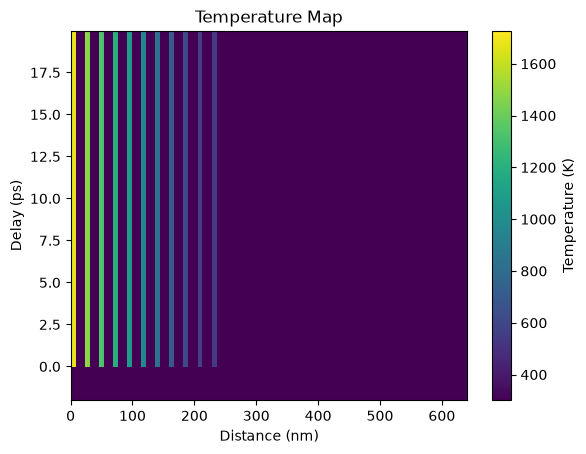

In [8]:
plt.figure()
plt.pcolormesh(
    res_temp.quantity("distances").to("nm"),
    res_temp.quantity("delays").to("ps"),
    res_temp.temp_map,
    shading="auto",
)
plt.colorbar(label=f"Temperature ({res_temp.unit('temp_map')})")
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map")
plt.show()

### Cache

The same simulation with the same parameters loads its result from the HDF5 file in the `cache_dir` instead of calculating it again, see the message below.

In [9]:
res_temp = h.get_temp_map(delays, 300 * u.K)

_temp_map_ loaded from file:
	temp_map_bcb96d6a20d146e74f474ea6b8c12fff_04402a9633f6df253b536a5d3663120a.h5


Any change of the parameters, e.g. of the fluence, changes the hash of the simulation, so that the temperature map is calculated again and saved to another file.

In [10]:
h.excitation = {
    "fluence": [10] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0] * u.ps,
}
res_temp_10 = h.get_temp_map(delays, 300 * u.K)
print(f"maximum temperature for 30 mJ/cm²: {np.max(res_temp.temp_map):.0f} K")
print(f"maximum temperature for 10 mJ/cm²: {np.max(res_temp_10.temp_map):.0f} K")

Surface incidence fluence scaled by factor 1.0000 due to incidence angle theta=90.00 deg
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 18.4 % and transmission of 11.0 %.
Elapsed time for _temperature_after_delta_excitation_: 0.022366 s
Elapsed time for _temp_map_: 0.050201 s
_temp_map_ saved to file:
	 temp_map_bcb96d6a20d146e74f474ea6b8c12fff_d616009052dd002d1a9ba722f22708ee.h5
maximum temperature for 30 mJ/cm²: 1727 K
maximum temperature for 10 mJ/cm²: 827 K


For the original fluence, the result is loaded from the cache again:

In [11]:
h.excitation = {
    "fluence": [30] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0] * u.ps,
}
res_temp = h.get_temp_map(delays, 300 * u.K)

_temp_map_ loaded from file:
	temp_map_bcb96d6a20d146e74f474ea6b8c12fff_04402a9633f6df253b536a5d3663120a.h5


### Plain Arrays

The `calc_*()` methods carry out the actual calculation and return plain numpy arrays without the cache and the metadata, which are calculated in any case, e.g. for a fit, which calculates many parameters only once.
The `get_*()` methods add the coordinates, units, and metadata to their results.

:::{hint}
Use the `calc_*()` methods for many calls, e.g. in loops or fits, see the [data fitting example](#example_data_fitting).
The metadata of every result of the `get_*()`, `homogeneous_*()`, and `inhomogeneous_*()` methods are generated for each calculation, where the structure as YAML takes about 20 ms, which can be longer than the calculation itself, e.g. of a homogeneous reflectivity.
:::

In [12]:
temp_map, delta_temp_map, _ = h.calc_temp_map(delays, 300 * u.K)
print(np.allclose(temp_map, res_temp.temp_map))

Surface incidence fluence scaled by factor 1.0000 due to incidence angle theta=90.00 deg
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 18.4 % and transmission of 11.0 %.
Elapsed time for _temperature_after_delta_excitation_: 0.026474 s
Elapsed time for _temp_map_: 0.055670 s
True


## Phonons

The results are passed on to the following simulations as a whole.
Here, {py:meth}`get_strain_map <udkm1Dsim.simulations.phonons.PhononNum.get_strain_map>` takes the `temp_map` and `delta_temp_map` from the result of the heat simulation as well as its coordinates.

In [13]:
p = ud.PhononNum(S, False)
p.cache_dir = cache_dir
p.save_data = True
p.disp_messages = True
res_strain = p.get_strain_map(delays, res_temp)
res_strain

Calculating linear thermal expansion ...
Calculating coherent dynamics with ODE solver ...


0it [00:00, ?it/s]

Elapsed time for _strain_map_: 0.404978 s
_strain_map_num_ saved to file:
	 strain_map_num_8bd34bc5592150aedd9a0c57118abc43_b1c5f64b09e28d61f741e577e5358667.h5


name,alias,kind,shape,dims,unit
strain_map,,data,"(440, 1638)","delays, distances",
delays,,coord,"(440,)",delays,s
distances,,coord,"(1638,)",distances,m


The inputs can still be given as plain arrays instead of a result, e.g. the `temp_map` and `delta_temp_map` of {py:meth}`calc_temp_map <udkm1Dsim.simulations.heat.Heat.calc_temp_map>` or of any other source.
As the arrays equal the ones of the result, the hash is the same and the strain map is loaded from the cache.
The coordinates, which are not given by plain arrays, are taken from the simulation, e.g. the `distances` of the layers, while the `delays` of an inhomogeneous scattering result are only known from a given result.

In [14]:
res_strain_arrays = p.get_strain_map(delays, res_temp.temp_map, res_temp.delta_temp_map)

_strain_map_num_ loaded from file:
	strain_map_num_8bd34bc5592150aedd9a0c57118abc43_b1c5f64b09e28d61f741e577e5358667.h5


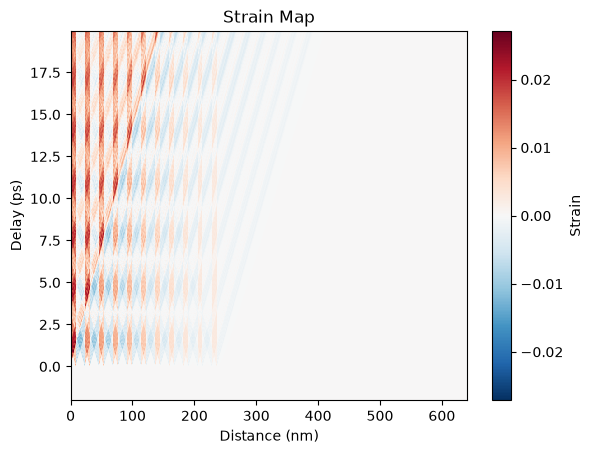

In [15]:
plt.figure()
plt.pcolormesh(
    res_strain.quantity("distances").to("nm"),
    res_strain.quantity("delays").to("ps"),
    res_strain.strain_map,
    cmap="RdBu_r",
    vmin=-np.max(res_strain.strain_map),
    vmax=np.max(res_strain.strain_map),
    shading="auto",
)
plt.colorbar(label="Strain")
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Strain Map")
plt.show()

## X-ray Diffraction

The scattering simulations calculate the homogeneous results for the sub-structures, e.g. for the static sample, by their `homogeneous_*()` methods and the inhomogeneous results for the maps of every layer by their `inhomogeneous_*()` methods, see the [dynamical X-ray example](#example_dynamical_xray).
Their results hold the coordinates `energy`, `qz`, and `theta` of the experiment, where `qz` and `theta` have the dimensions `energy` and `angles`.
The entries of the scattering results have short aliases, e.g. `res_static.R` for `res_static.reflectivity`, which are listed in the table of the result and by its {py:attr}`aliases <udkm1Dsim.simulations.result.Result.aliases>`.

In [16]:
dyn = ud.XrayDyn(S, False)
dyn.cache_dir = cache_dir
dyn.save_data = True
dyn.disp_messages = True
dyn.energy = np.r_[8047] * u.eV
dyn.qz = np.r_[3.1:3.3:0.0005] / u.angstrom

res_static = dyn.homogeneous_reflectivity()
res_static

Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 0.041338 s


name,alias,kind,shape,dims,unit
reflectivity,R,data,"(1, 400)","energy, angles",
sub_structure_matrices,A,data,list,,
energy,,coord,"(1,)",energy,eV
qz,,coord,"(1, 400)","energy, angles",1/nm
theta,,coord,"(1, 400)","energy, angles",deg


The result of the phonon simulation is passed on as `strain_map`, so that the inhomogeneous reflectivity also holds its `delays`.
The strains of the layers are discretized by the `strain_vectors` of {py:meth}`calc_reduced_strains_per_unique_layer <udkm1Dsim.simulations.phonons.Phonon.calc_reduced_strains_per_unique_layer>` to save computational time, see the [dynamical X-ray example](#example_dynamical_xray).

The laser pulse heats the SRO layers, which expand and compress the STO layers in between.
This excites the optical superlattice phonon mode, which modulates the intensity of the superlattice Bragg peaks, as discussed in detail by {cite:t}`herzog2012b`.

:::{admonition} Reference {cite}`herzog2012b`
:class: seealso
M. Herzog, D. Schick, W. Leitenberger, R. Shayduk, R. M. van der Veen, C. J. Milne, S. L. Johnson, I. Vrejoiu, and M. Bargheer, *Tailoring interference and nonlinear manipulation of femtosecond x-rays*, [New J. Phys. 14, 013004 (2012)](https://doi.org/10.1088/1367-2630/14/1/013004)
:::

In [17]:
strain_vectors = p.calc_reduced_strains_per_unique_layer(res_strain)
res_transient = dyn.inhomogeneous_reflectivity(res_strain, strain_vectors)
res_transient

Calculating _inhomogeneous_reflectivity_dyn_ ...
Calculating _all_ref_trans_matrices_dyn_ ...
Calculate all _ref_trans_matrices_ ...
Elapsed time for _ref_trans_matrices_: 1.460942 s
Elapsed time for _all_ref_trans_matrices_dyn_: 1.474636 s
_all_ref_trans_matrices_dyn_ saved to file:
	 all_ref_trans_matrices_dyn_cf9632da8293544599207cf02f401cd8_a0d7b6b55dbd396aa2e284fce1c4369c.h5


Progress:   0%|          | 0/440 [00:00<?, ?it/s]

Elapsed time for _inhomogeneous_reflectivity_dyn_: 40.279779 s
_inhomogeneous_reflectivity_dyn_ saved to file:
	 inhomogeneous_reflectivity_dyn_cf9632da8293544599207cf02f401cd8_015fcfeedff24fb853abceb75e1d0d5c.h5


name,alias,kind,shape,dims,unit
reflectivity,R,data,"(440, 1, 400)","delays, energy, angles",
delays,,coord,"(440,)",delays,s
energy,,coord,"(1,)",energy,eV
qz,,coord,"(1, 400)","energy, angles",1/nm
theta,,coord,"(1, 400)","energy, angles",deg


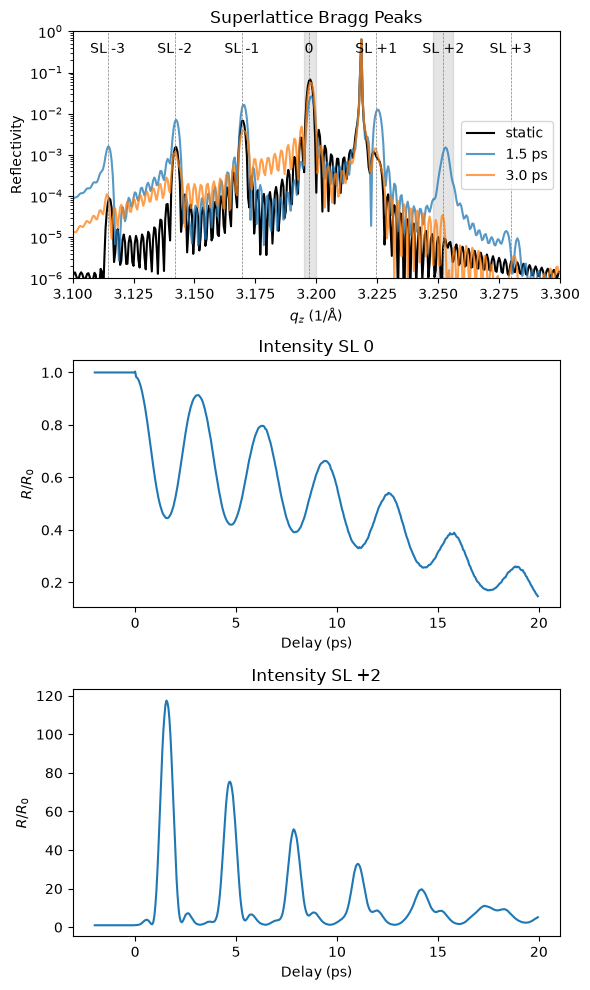

In [18]:
qz = res_transient.quantity("qz", "1/angstrom")[0, :]
res_delays = res_transient.quantity("delays", "ps")
# integrated intensities of two superlattice Bragg peaks
# normalized to their intensities before the excitation
peaks = {
    "SL 0": np.array([3.195, 3.2]) / u.angstrom,
    "SL +2": np.array([3.248, 3.256]) / u.angstrom,
}
intensities = {}
# positions of the superlattice Bragg peaks of the order m around the (002) Bragg
# peak of the average lattice, i.e. the order 2*58 of the DL period
d_DL = 20 * c_SRO + 38 * c_STO
SL_peaks = {m: (2 * np.pi * (2 * 58 + m) / d_DL).to("1/angstrom") for m in range(-3, 4)}
for label, (qz_min, qz_max) in peaks.items():
    intensity = np.sum(res_transient.R[:, 0, (qz > qz_min) & (qz < qz_max)], axis=1)
    intensities[label] = intensity / np.mean(intensity[res_delays < 0 * u.ps])

plt.figure(figsize=[6, 10])
plt.subplot(3, 1, 1)
plt.semilogy(qz, res_static.R[0, :], "k", label="static")
for delay in [1.5, 3] * u.ps:
    i = np.argmin(np.abs(res_delays - delay))
    plt.semilogy(qz, res_transient.R[i, 0, :], label=f"{res_delays[i]:.1f~P}", alpha=0.75)
for qz_min, qz_max in peaks.values():
    plt.axvspan(qz_min, qz_max, color="gray", alpha=0.2)
for m, qz_m in SL_peaks.items():
    plt.axvline(qz_m, color="gray", ls="--", lw=0.5)
    plt.text(qz_m.magnitude, 0.3, f"SL {m:+d}" if m else "0", ha="center")
plt.ylim(1e-6, 1)
plt.xlim(3.1, 3.3)
plt.xlabel(r"$q_z$ (1/Å)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Superlattice Bragg Peaks")

for j, (label, intensity) in enumerate(intensities.items()):
    plt.subplot(3, 1, j + 2)
    plt.plot(res_delays, intensity)
    plt.xlabel("Delay (ps)")
    plt.ylabel(r"$R / R_0$")
    plt.title(f"Intensity {label}")
plt.tight_layout()
plt.show()

## Cache and HDF5 Files

All results of the `get_*()` methods and the inhomogeneous scattering results are saved to HDF5 files in the `cache_dir`, which are named by the hash of the simulation parameters and the structure.
If a simulation is repeated with the same parameters and `force_recalc=False`, the result is loaded from this file instead of being calculated again.

In [19]:
sorted(listdir(cache_dir))

['all_ref_trans_matrices_dyn_cf9632da8293544599207cf02f401cd8_a0d7b6b55dbd396aa2e284fce1c4369c.h5',
 'inhomogeneous_reflectivity_dyn_cf9632da8293544599207cf02f401cd8_015fcfeedff24fb853abceb75e1d0d5c.h5',
 'strain_map_num_8bd34bc5592150aedd9a0c57118abc43_b1c5f64b09e28d61f741e577e5358667.h5',
 'temp_map_bcb96d6a20d146e74f474ea6b8c12fff_04402a9633f6df253b536a5d3663120a.h5',
 'temp_map_bcb96d6a20d146e74f474ea6b8c12fff_d616009052dd002d1a9ba722f22708ee.h5']

The files can be loaded by {py:meth}`Result.load <udkm1Dsim.simulations.result.Result.load>` without the simulation and any result can be saved to a file by {py:meth}`save <udkm1Dsim.simulations.result.Result.save>`, e.g. to share it.
The data and coordinates are stored as datasets with their units as attributes, where the 1D coordinates are attached as dimension scales, and the metadata as attributes, so that the files can also be inspected with any HDF5 viewer, e.g. [h5web](https://h5web.panosc.eu/).

In [20]:
filename = path.join(cache_dir, "transient_reflectivity.h5")
res_transient.save(filename)
res_loaded = ud.Result.load(filename)
res_loaded

name,alias,kind,shape,dims,unit
reflectivity,R,data,"(440, 1, 400)","delays, energy, angles",
delays,,coord,"(440,)",delays,s
energy,,coord,"(1,)",energy,eV
qz,,coord,"(1, 400)","energy, angles",1/nm
theta,,coord,"(1, 400)","energy, angles",deg


Optionally, a result is converted to an [xarray](https://docs.xarray.dev) dataset, which requires `xarray` to be installed, e.g. for its labeled indexing and plotting.

In [21]:
try:
    dataset = res_temp.to_xarray()
    print(dataset)
except ImportError:
    print("xarray is not installed")

xarray is not installed


## Overview of all Results

The following tree lists the entries of the results of all `get_*()`, `homogeneous_*()`, and `inhomogeneous_*()` methods of every simulation, each with its aliases after `|`, the names of its dimensions, and its unit in brackets.
The tree is generated by calling all methods for a small structure and a few delays, so that it is always in sync with the code.
The magnetization simulations use a small Ni film, as unit cells are not supported by them yet, and the methods of the multilayer formalisms `Parratt`, {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>`, {py:class}`Stepanov <udkm1Dsim.simulations.scattering.stepanov.Stepanov>`, {py:class}`BerremanElzo <udkm1Dsim.simulations.scattering.berreman.BerremanElzo>`, and {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>` are the ones of their base class {py:class}`MultilayerScattering <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering>`, which are calculated here by {py:class}`Parratt <udkm1Dsim.simulations.scattering.parratt.Parratt>`.
In the same way, the methods of {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>`, {py:class}`iLLG <udkm1Dsim.simulations.magnetization.iLLG>`, and {py:class}`LLB <udkm1Dsim.simulations.magnetization.LLB>` are the ones of their base class {py:class}`Magnetization <udkm1Dsim.simulations.magnetization.Magnetization>`, which are calculated by `LLG`.
The `calc_*()` methods return the same data as plain arrays, e.g. for fits.

In [22]:
from itertools import groupby

from IPython.display import HTML

# all results of the simulations of a small structure for a few delays
S_small = ud.Structure("small SRO on STO")
S_small.add_sub_structure(SRO, 5)
S_small.add_sub_structure(STO_sub, 5)
delays_small = np.r_[-1:2:1] * u.ps
options = {"save_data": False, "disp_messages": False, "progress_bar": False}

heat = ud.Heat(S_small, True, **options)
heat.excitation = {
    "fluence": [5] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0] * u.ps,
}
pnum = ud.PhononNum(S_small, True, **options)
pana = ud.PhononAna(S_small, True, **options)
# a small magnetic Ni film for the magnetization, as unit cells are not supported yet
layer_Ni = ud.Layer(
    "Ni",
    "Nickel",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=8910 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=444 * u.J / (u.kg * u.K), therm_cond=90 * u.W / (u.m * u.K)
    ),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.3 + 8.9j)),
    magnetic=ud.MagneticParameters(
        eff_spin=0.5,
        curie_temp=630 * u.K,
        mag_moment=0.6 * u.bohr_magneton,
        mag_saturation=4.9e5 * u.A / u.m,
        gilbert_damping=0.03,
        magnetization=(1, 0, 0),
    ),
)
S_Ni = ud.Structure("Ni film")
S_Ni.add_sub_structure(layer_Ni, 5)
heat_Ni = ud.Heat(S_Ni, True, **options)
heat_Ni.excitation = heat.excitation
llg = ud.LLG(S_Ni, True, **options)
kin = ud.XrayKin(S_small, True, **options)
dyn = ud.XrayDyn(S_small, True, **options)
parratt = ud.Parratt(S_small, True, **options)
for sim in (kin, dyn, parratt):
    sim.energy = np.r_[8047] * u.eV
    sim.qz = np.r_[3.1:3.3:0.05] / u.angstrom

res = heat.get_temp_map(delays_small, 300 * u.K)
res_ana = pana.get_strain_map(delays_small, res)
res_Ni = heat_Ni.get_temp_map(delays_small, 300 * u.K)
calls = [
    ("Heat", "get_temp_map", res),
    ("Heat", "get_energy_map", heat.get_energy_map(res)),
    ("Heat", "get_energy_flux_map", heat.get_energy_flux_map(res)),
    (
        "Heat",
        "get_temperature_after_delta_excitation",
        heat.get_temperature_after_delta_excitation(1, 300),
    ),
    ("PhononNum", "get_strain_map", pnum.get_strain_map(delays_small, res)),
    ("PhononAna", "get_strain_map", res_ana),
    ("PhononAna", "get_eigenproblem", pana.get_eigenproblem()),
    ("PhononAna", "get_energy_per_eigenmode", pana.get_energy_per_eigenmode(res_ana)),
    ("Magnetization", "get_magnetization_map", llg.get_magnetization_map(delays_small)),
    (
        "Magnetization",
        "get_sublattice_magnetization_map",
        llg.get_sublattice_magnetization_map(delays_small),
    ),
    ("Magnetization", "get_equilibrium_magnetization", llg.get_equilibrium_magnetization()),
    ("Magnetization", "get_mean_field_mag_map", llg.get_mean_field_mag_map(res_Ni)),
    (
        "Magnetization",
        "get_sublattice_mean_field_mag_map",
        llg.get_sublattice_mean_field_mag_map(res_Ni),
    ),
    ("XrayKin", "homogeneous_reflectivity", kin.homogeneous_reflectivity()),
    ("XrayDyn", "homogeneous_reflectivity", dyn.homogeneous_reflectivity()),
    ("XrayDyn", "inhomogeneous_reflectivity", dyn.inhomogeneous_reflectivity(res_ana)),
]
# the methods of all multilayer formalisms are the ones of their base class
for kind, maps in [("homogeneous", ()), ("inhomogeneous", (res_ana,))]:
    for method in ["jones_matrices", "reflectivity_transmissivity", "rotation_ellipticity"]:
        result = getattr(parratt, f"{kind}_{method}")(*maps)
        calls.append(("MultilayerScattering", f"{kind}_{method}", result))

rows = [
    (simulation, method, name, result)
    for simulation, method, result in calls
    for name in result.keys()
]

# HTML tree of the simulations, their methods, and the entries of the results
# with their aliases, dimensions, and units
html = []
for simulation, simulation_rows in groupby(rows, key=lambda row: row[0]):
    html.append(f"<details open><summary><b><code>{simulation}</code></b></summary><ul>")
    for method, method_rows in groupby(simulation_rows, key=lambda row: row[1]):
        html.append(f"<li><code>{method}()</code><ul>")
        for _, _, name, result in method_rows:
            aliases = "".join(f" | <code>{alias}</code>" for alias in result.aliases_of(name))
            dims = " × ".join(result.dims(name))
            unit = f" ({result.unit(name)})" if result.unit(name) else ""
            info = f'<span style="color: gray">{dims}{unit}</span>'
            html.append(f"<li><code>{name}</code>{aliases} &nbsp; {info}</li>")
        html.append("</ul></li>")
    html.append("</ul></details>")
HTML("\n".join(html))